# Transporte Público · DTPM GTFS — Horarios y recorridos de Santiago

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Data-Observatory/datopia-notebooks/blob/main/notebooks/transporte/dtpm/demo.ipynb)
[![Licencia](https://img.shields.io/badge/licencia-MIT-blue.svg)](../../../LICENSE)
[![Dataset](https://img.shields.io/badge/dataset-dtpm-green.svg)]()
[![Actualización](https://img.shields.io/badge/actualización-diaria-brightgreen.svg)]()
[![Python](https://img.shields.io/badge/python-3.10%2B-blue.svg)]()

---

## Descripción

Acceso a los **feeds GTFS del Directorio de Transporte Público Metropolitano (DTPM)**: rutas, paradas,
viajes, horarios, frecuencias y trazados del transporte público de la Región Metropolitana, a través
del **Datopia Lakehouse**. Se publican **todos los feeds desde 2014** (el vigente y los históricos
anuales) como 15 tablas Parquet; las paradas y los trazados son GeoParquet 1.1.

El acceso es directo vía S3 con credenciales temporales, sin descarga de archivos.

> **Nota:** estas tablas todavía no aparecen en el catálogo (`datamodel.json`); la entrada de catálogo
> llega después. Por eso este notebook lee las rutas S3 directamente, sin descubrirlas desde el catálogo.

> **Regla de oro:** hay un feed por cada versión publicada por el DTPM y las tablas grandes guardan **una
> copia completa por feed** (`gtfs-stop-times` tiene más de 100 millones de filas, `gtfs-shapes` más de 60
> millones). **Siempre se filtra por `feed_id`** antes de tocar esas tablas. Todo este notebook usa
> consultas baratas: listados S3, pies de archivo (*footers*) de Parquet y un feed a la vez.

### Contenido

1. Configuración y autenticación
2. Las 15 tablas y su escala
3. Los feeds: uno por versión publicada desde 2014
4. ¿Qué feed rige en una fecha? La tabla `gtfs-vigencia`
5. Rutas y paradas de un feed
6. Viajes y frecuencias de una ruta
7. Trazados (`gtfs-shapes-lineas`): un ejemplo espacial
8. Cobertura de la vigencia: los días sin feed
9. Trampas conocidas

### Requisitos

Cuenta en el Datopia Lakehouse · Python 3.10+ · Las dependencias se instalan automáticamente

In [1]:
# @title Instalación de dependencias
import importlib, importlib.util, subprocess, sys

for paquete in ["requests", "duckdb", "pandas", "matplotlib"]:
    if importlib.util.find_spec(paquete) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])

import json, os, re, time, getpass, pathlib
from datetime import datetime
from zoneinfo import ZoneInfo
import requests, duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

EN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

print("Dependencias listas.")

Dependencias listas.


In [2]:
# @title Configuración de credenciales
print(f"Entorno: {'Google Colab' if EN_COLAB else 'local'}")

URL_API = "https://ee98cnfz7e.execute-api.us-west-2.amazonaws.com/prod"

if EN_COLAB:
    EMAIL = input("Email: ").strip()
    PASSWORD = getpass.getpass("Contraseña: ")
else:
    ruta_cfg = pathlib.Path("../../../config.json")
    if not ruta_cfg.exists():
        raise FileNotFoundError(
            f"Archivo de configuración no encontrado en {ruta_cfg.resolve()}.\n"
            "Copia config.example.json → config.json y completa tus credenciales."
        )
    cfg = json.loads(ruta_cfg.read_text())
    EMAIL = cfg.get("test_user", {}).get("email") or input("Email: ").strip()
    PASSWORD = cfg.get("test_user", {}).get("password") or getpass.getpass("Contraseña: ")

print(f"API    : {URL_API}")

Entorno: local
API    : https://ee98cnfz7e.execute-api.us-west-2.amazonaws.com/prod


---
## 1. Autenticación y conexión a S3

In [3]:
# Iniciar sesión y obtener credenciales temporales S3
resp_login = requests.post(
    f"{URL_API}/auth/login",
    json={"email": EMAIL, "password": PASSWORD},
    timeout=30,
)
resp_login.raise_for_status()
token = resp_login.json()["id_token"]

resp_s3 = requests.post(
    f"{URL_API}/auth/session/s3",
    headers={"Authorization": f"Bearer {token}"},
    timeout=30,
)
resp_s3.raise_for_status()
creds = resp_s3.json()

print("Sesión iniciada")
print(f"  Bucket : {creds['bucket']}")
print(f"  Región : {creds['region']}")
print(f"  Expira : {creds['expires_at']}")

Sesión iniciada
  Bucket : do-datopia
  Región : us-west-2
  Expira : 2026-11-12T22:47:19+00:00


In [4]:
# Configurar DuckDB con credenciales S3
con = duckdb.connect()
con.execute(f"""
    CREATE OR REPLACE SECRET s3 (
        TYPE          S3,
        KEY_ID        '{creds["access_key_id"]}',
        SECRET        '{creds["secret_access_key"]}',
        SESSION_TOKEN '{creds["session_token"]}',
        REGION        '{creds["region"]}'
    )
""")
# Extensión espacial: solo la necesitan gtfs-stops y gtfs-shapes-lineas (columna geometry)
try:
    con.execute("LOAD spatial")
except Exception:
    con.execute("INSTALL spatial; LOAD spatial")
con.execute("SET TimeZone = 'UTC'")
con.execute("SET enable_progress_bar = false")   # sin barras de progreso en las salidas

# Los 15 tipos viven bajo la misma fuente (fuente=dtpm), uno por carpeta tipo=gtfs-<nombre>
BASE = (
    f"s3://{creds['bucket']}/categoria=transporte/pais=cl"
    f"/fuente=dtpm"
)
print(f"DuckDB {duckdb.__version__} conectado a S3.")

DuckDB 1.5.3 conectado a S3.


### Función de ayuda para leer una tabla

Cada tabla vive en `{BASE}/tipo=gtfs-<nombre>/version=v1/`. Hay dos formas de guardarla:

- **Tablas por feed** (`trips`, `stop-times`, `stops`, `shapes`, `shapes-lineas`, `frequencies`): **un
  archivo por feed**, `part-<feed_id con - en vez de _>-00000.parquet`. Si se conoce el `feed_id`, se abre
  solo ese archivo (rápido y barato).
- **Tablas completas** (`feeds`, `vigencia`, `agency`, `routes`, `calendar`, `calendar-dates`,
  `pathways`, `levels`, `transfers`): un solo archivo con todos los feeds (el nombre cambia en cada
  actualización, por eso se lee con `*.parquet`); se filtran con `WHERE feed_id = ...`.

`hive_partitioning=false` evita que DuckDB invente columnas (`categoria`, `fuente`, `tipo`…) a partir de las
carpetas, ya que estas tablas no tienen particiones.

In [5]:
# @title Función `tabla()`: expresión read_parquet de una tabla GTFS
TABLAS_POR_FEED = {"trips", "stop-times", "stops", "shapes", "shapes-lineas", "frequencies"}

def tabla(tipo, feed_id=None):
    """Devuelve `read_parquet(...)` de la tabla gtfs-<tipo>.

    - Tabla por feed + feed_id: abre solo el archivo de ese feed.
    - Cualquier otro caso: lee todos los archivos de la tabla (usar WHERE feed_id = ... y, para las
      tablas por feed, no usar sin feed_id salvo para contar filas, que solo lee los footers).
    """
    base = f"{BASE}/tipo=gtfs-{tipo}/version=v1"
    if feed_id and tipo in TABLAS_POR_FEED:
        archivo = f"part-{feed_id.replace('_', '-')}-00000.parquet"
        return f"read_parquet('{base}/{archivo}', hive_partitioning=false)"
    return f"read_parquet('{base}/*.parquet', hive_partitioning=false)"

def consulta(sql):
    """Ejecuta SQL en DuckDB y devuelve un DataFrame de pandas."""
    return con.execute(sql).df()

print(tabla("stop-times", "GTFS_20261003"))

read_parquet('s3://do-datopia/categoria=transporte/pais=cl/fuente=dtpm/tipo=gtfs-stop-times/version=v1/part-GTFS-20261003-00000.parquet', hive_partitioning=false)


---
## 2. Las 15 tablas y su escala

| Tabla (`tipo=`) | Qué contiene | Clave |
|---|---|---|
| `gtfs-feeds` | Un registro por feed publicado (fechas declaradas, tipo de feed, hashes) | `feed_id` |
| `gtfs-vigencia` | **Qué feed rige cada día** (derivada, ver sección 4) | `fecha_servicio` |
| `gtfs-agency` | Operadores (Metro, EFE, buses RED…) | `feed_id`, `agency_id` |
| `gtfs-routes` | Rutas (servicios) | `feed_id`, `route_id` |
| `gtfs-trips` | Viajes de cada ruta | `feed_id`, `trip_id` |
| `gtfs-stop-times` | Hora de paso de cada viaje por cada parada | `feed_id`, `trip_id`, `stop_sequence` |
| `gtfs-stops` | Paradas y estaciones (**GeoParquet**, puntos) | `feed_id`, `stop_id` |
| `gtfs-shapes` | Puntos de los trazados, como columnas planas | `feed_id`, `shape_id`, `shape_pt_sequence` |
| `gtfs-shapes-lineas` | Un trazado (LineString) por `shape_id` (**GeoParquet**, derivada de `shapes`) | `feed_id`, `shape_id` |
| `gtfs-frequencies` | Frecuencias (cada cuántos segundos sale un bus) | `feed_id`, `trip_id`, `start_time` |
| `gtfs-calendar` / `gtfs-calendar-dates` | Días de la semana en que corre cada servicio y excepciones | `feed_id`, `service_id` (`date`) |
| `gtfs-pathways` / `gtfs-levels` / `gtfs-transfers` | Accesos y niveles de estaciones (desde 2024-10 / 2026-02) y transbordos (solo 2024-10 a 2026-02) | |

Todas las tablas llevan `feed_id`. Los nombres de columna GTFS se conservan tal cual.

Las cifras salen del `manifest.json` de cada tabla (un archivo pequeño; no se leen los datos):

In [6]:
# Escala de cada tabla: manifest.json de cada tipo (filas, archivos y tamaño en disco)
tablas = consulta(f"""
    SELECT replace(tipo, 'gtfs-', '')                          AS tabla,
           row_count                                           AS filas,
           part_count                                          AS archivos,
           ROUND(list_sum(list_transform(parts, p -> p.bytes)) / 1e6, 1) AS mb
    FROM read_json('{BASE}/tipo=gtfs-*/version=v1/manifest.json', union_by_name = true)
    ORDER BY filas DESC
""")
tablas["filas"] = tablas["filas"].map("{:,}".format)
tablas

,tabla,filas,archivos,mb
0,stop-times,"113,969,330",147,966.9
1,shapes,"61,492,596",147,235.5
2,trips,"2,168,750",147,7.2
3,frequencies,"2,043,149",147,5.9
4,stops,"1,812,074",147,75.6
5,shapes-lineas,"140,582",147,318.5
6,pathways,"103,320",1,0.2
7,transfers,"61,000",1,0.0
8,routes,"59,220",1,0.1
9,levels,"4,740",1,0.0


Dos tablas son enormes: `stop-times` (≈114 M de filas) y `shapes` (≈61 M); `trips`, `stops` y `frequencies` tienen
≈2 M cada una. Contar filas es barato (se lee solo el pie del archivo Parquet), pero **traer columnas de
`stop-times` o `shapes` sin filtrar por `feed_id` baja cientos de MB**. En este notebook eso nunca ocurre.

---
## 3. Los feeds: uno por versión publicada desde 2014

La clave de un feed es **`feed_id`** (el nombre del zip publicado, normalizado: `GTFS_20261003`).
**`feed_version` es la etiqueta del DTPM y se repite** (la sección 9 muestra ejemplos): nunca unir por
`feed_version`.

In [7]:
# Todos los feeds publicados (tabla chica: 1 fila por feed)
feeds = consulta(f"""
    SELECT feed_id, feed_version, feed_kind, feed_start_date, feed_end_date, fecha_inicio, fecha_fin
    FROM {tabla('feeds')}
    ORDER BY feed_start_date, feed_id
""")
print(f"Feeds publicados: {len(feeds)}  ·  primero: {feeds['feed_id'].iloc[0]}  ·  último: {feeds['feed_id'].iloc[-1]}")
feeds.tail(8)

Feeds publicados: 147  ·  primero: GTFS_20140101  ·  último: GTFS_20261003


,feed_id,feed_version,feed_kind,feed_start_date,feed_end_date,fecha_inicio,fecha_fin
139,GTFS_20260314,V160.20260314,regular,2026-03-14,2026-12-31,2026-03-14,2026-03-21
140,GTFS_20260321_v3,V161.20260314,regular,2026-03-21,2026-12-31,2026-03-21,2026-04-18
141,GTFS_20260418,V162.20260418,regular,2026-04-18,2026-12-31,2026-04-18,2026-04-25
142,GTFS_20260418_Maraton,V163.20260425,evento_especial,2026-04-25,2026-12-31,2026-04-26,2026-04-27
143,GTFS_20260425,V164.20260425,regular,2026-04-25,2026-12-31,2026-04-25,2026-05-30
144,GTFS_20260530_v2,V165.20260530,regular,2026-05-30,2026-12-31,2026-05-30,2026-08-29
145,GTFS_20260829,V167.20260829,regular,2026-08-29,2026-12-31,2026-08-29,2026-10-03
146,GTFS_20261003,V168.20261003,regular,2026-10-03,2026-12-31,2026-10-03,NaT


Qué significa cada fecha de `gtfs-feeds`:

- `feed_start_date` / `feed_end_date`: lo que el feed **declara** (ambas inclusivas). Los feeds se traslapan,
  algunos parten antes de la fecha de su nombre (efecto retroactivo) y entre algunos hay días sin cobertura.
- `fecha_inicio` / `fecha_fin`: intervalo de la serie de feeds (`fecha_fin` es **exclusiva**; `NULL` = aún no hay feed posterior).
- **Ninguna de las dos sirve para resolver "qué feed rige un día"**: para eso está `gtfs-vigencia` (sección 4).
- `feed_kind`: `regular` o `evento_especial` (feed publicado para un evento de un día: maratón, elecciones).

In [8]:
# Feeds por tipo y por año; el nombre del feed NO es la fecha de inicio
resumen = consulta(f"""
    SELECT year(feed_start_date) AS anio,
           COUNT(*)                                        AS feeds,
           COUNT(*) FILTER (WHERE feed_kind <> 'regular')  AS especiales,
           COUNT(*) FILTER (WHERE feed_start_date <> strptime(regexp_extract(feed_id, '(\\d{{8}})', 1), '%Y%m%d')::DATE)
                                                           AS inicio_distinto_al_nombre
    FROM {tabla('feeds')}
    GROUP BY anio ORDER BY anio
""")
resumen.T

,0,1,2,3,4,5,6,7,8,9,10,11,12
anio,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
feeds,8,5,7,4,6,7,9,5,11,32,14,24,15
especiales,0,0,0,0,0,0,0,0,0,1,1,1,1
inicio_distinto_al_nombre,5,4,5,3,3,5,5,4,1,0,1,0,1


---
## 4. ¿Qué feed rige en una fecha? La tabla `gtfs-vigencia`

`gtfs-vigencia` tiene **una fila por día de servicio** (`fecha_servicio`, día calendario de Santiago) con el
`feed_id` que rige ese día. Ya aplica todas las reglas del DTPM (cuál feed gana cuando se traslapan, los
feeds de eventos especiales de un día, y que `feed_end_date` solo corta, nunca elige). Una fecha **sin fila no
tiene feed**.

**Siempre se resuelve una fecha a un feed con `gtfs-vigencia`**, nunca con `feed_start_date`/`feed_end_date`.

In [9]:
# ¿Qué feed rige en cada fecha? Una sola consulta para varias fechas (en vez de un loop)
hoy = datetime.now(ZoneInfo("America/Santiago")).date().isoformat()
fechas = [
    ("hoy (Santiago)", hoy),
    ("lunes normal", "2026-05-04"),
    ("maratón 2026 (evento especial)", "2026-04-26"),
    ("un día sin feed", "2015-08-15"),
]
valores = ", ".join(f"('{etiqueta}', DATE '{fecha}')" for etiqueta, fecha in fechas)

consulta(f"""
    SELECT d.etiqueta, d.fecha, v.feed_id, v.feed_kind
    FROM (VALUES {valores}) AS d(etiqueta, fecha)
    LEFT JOIN {tabla('vigencia')} v ON v.fecha_servicio = d.fecha
""")

,etiqueta,fecha,feed_id,feed_kind
0,maratón 2026 (evento especial),2026-04-26,GTFS_20260418_Maraton,evento_especial
1,lunes normal,2026-05-04,GTFS_20260425,regular
2,hoy (Santiago),2026-11-12,GTFS_20261003,regular
3,un día sin feed,2015-08-15,None,None


Para el resto del notebook se fija una fecha de análisis y se resuelve su feed. La función falla con un
mensaje claro si la fecha no tiene feed (es un caso real, ver sección 8).

In [10]:
def feed_de_la_fecha(fecha):
    """feed_id que rige en `fecha` (YYYY-MM-DD), según gtfs-vigencia."""
    fila = con.execute(
        f"SELECT feed_id FROM {tabla('vigencia')} WHERE fecha_servicio = DATE '{fecha}'"
    ).fetchone()
    if fila is None:
        raise ValueError(f"No hay feed para {fecha} (día sin cobertura en gtfs-vigencia).")
    return fila[0]

FECHA = "2026-05-04"          # cambia la fecha para ver otro feed
FEED = feed_de_la_fecha(FECHA)
print(f"Fecha de análisis: {FECHA}  →  feed {FEED}")

Fecha de análisis: 2026-05-04  →  feed GTFS_20260425


---
## 5. Rutas y paradas de un feed

Las tablas completas (`routes`, `agency`) se filtran por `feed_id`; las tablas por feed (`stops`) se abren
directo con el archivo del feed.

In [11]:
# Rutas del feed por operador y tipo (GTFS route_type: 0 tren ligero/tranvía, 1 metro, 3 bus)
consulta(f"""
    SELECT a.agency_name AS operador, r.route_type, COUNT(*) AS rutas
    FROM {tabla('routes')} r
    LEFT JOIN {tabla('agency')} a USING (feed_id, agency_id)
    WHERE r.feed_id = '{FEED}'
    GROUP BY ALL ORDER BY rutas DESC
""")

,operador,route_type,rutas
0,Red Metropolitana de Movilidad,3,415
1,Metro de Santiago,1,7
2,EFE Trenes de Chile,0,2
3,Bus de Acercamiento Aeropuerto,3,1


In [12]:
# Paradas del feed por location_type (NULL/0 = parada, 1 = estación, 2 = acceso, 3/4 = nodos sin coordenadas)
consulta(f"""
    SELECT location_type, COUNT(*) AS paradas, COUNT(lon) AS con_coordenadas
    FROM {tabla('stops', FEED)}
    GROUP BY location_type ORDER BY location_type
""")

,location_type,paradas,con_coordenadas
0,0,286,286
1,1,126,126
2,2,298,298
3,3,5031,0
4,4,534,0
5,<NA>,12092,12092


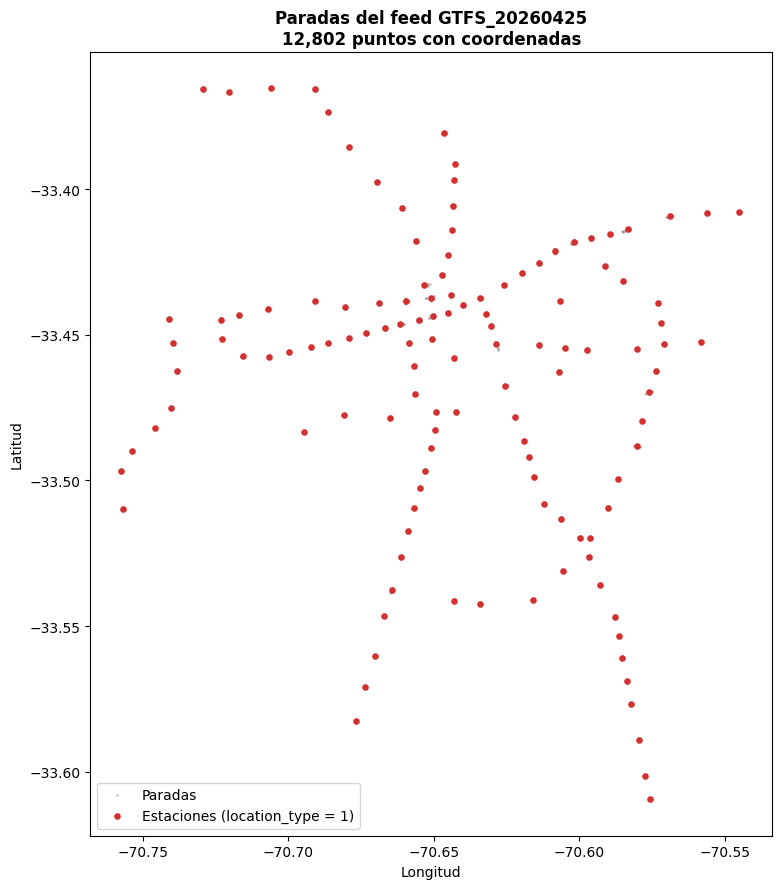

In [13]:
# Mapa de paradas: usa lon/lat (columnas derivadas de geometry; no necesita extensión espacial)
paradas = consulta(f"""
    SELECT lon, lat, location_type FROM {tabla('stops', FEED)} WHERE lon IS NOT NULL
""")
es_estacion = paradas["location_type"] == 1

fig, ax = plt.subplots(figsize=(8, 9))
ax.scatter(paradas.loc[~es_estacion, "lon"], paradas.loc[~es_estacion, "lat"], s=1, c="#9e9e9e", alpha=0.5, label="Paradas")
ax.scatter(paradas.loc[es_estacion, "lon"], paradas.loc[es_estacion, "lat"], s=14, c="#d32f2f", label="Estaciones (location_type = 1)")
ax.set_title(f"Paradas del feed {FEED}\n{len(paradas):,} puntos con coordenadas", fontweight="bold")
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud"); ax.set_aspect("equal"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

---
## 6. Viajes y frecuencias de una ruta

Dentro del feed que rige, los días de la semana en que corre cada servicio (`service_id`) los deciden
`gtfs-calendar` (días de la semana y rango de fechas) y `gtfs-calendar-dates` (excepciones: `1` agrega el
servicio ese día, `2` lo quita).

In [14]:
def servicios_del_dia(feed_id, fecha):
    """service_id que corren en `fecha` dentro de `feed_id` (calendar + excepciones de calendar_dates)."""
    return consulta(f"""
        WITH regulares AS (
            SELECT service_id FROM {tabla('calendar')}
            WHERE feed_id = '{feed_id}' AND DATE '{fecha}' BETWEEN start_date AND end_date
              AND [monday, tuesday, wednesday, thursday, friday, saturday, sunday][isodow(DATE '{fecha}')] = 1
        ),
        excepciones AS (
            SELECT service_id, exception_type FROM {tabla('calendar-dates')}
            WHERE feed_id = '{feed_id}' AND date = DATE '{fecha}'
        )
        SELECT service_id FROM regulares
        WHERE service_id NOT IN (SELECT service_id FROM excepciones WHERE exception_type = 2)
        UNION
        SELECT service_id FROM excepciones WHERE exception_type = 1
        ORDER BY service_id
    """)["service_id"].tolist()

SERVICIOS = servicios_del_dia(FEED, FECHA)
print(f"Servicios que corren el {FECHA}: {SERVICIOS}")

Servicios que corren el 2026-05-04: ['L', 'LJ']


In [15]:
# Ruta a analizar: se busca por su nombre corto
RUTA = "210"
ruta = consulta(f"""
    SELECT route_id, route_short_name, route_long_name, route_type, agency_id
    FROM {tabla('routes')} WHERE feed_id = '{FEED}' AND route_short_name = '{RUTA}'
""")
RUTA_ID = ruta["route_id"].iloc[0]
ruta

,route_id,route_short_name,route_long_name,route_type,agency_id
0,210,210,Estacion Central - Puente Alto,3,RM


In [16]:
# Frecuencias de la ruta en el día: trips + frequencies del feed (un archivo cada una), solo los servicios activos
lista_servicios = ", ".join(f"'{s}'" for s in SERVICIOS)
frecuencias = consulta(f"""
    SELECT t.direction_id, t.trip_headsign AS destino, t.service_id,
           f.start_time, f.end_time, f.start_time_s, f.end_time_s, f.headway_secs,
           ROUND(f.headway_secs / 60.0, 1) AS intervalo_min
    FROM {tabla('trips', FEED)} t
    JOIN {tabla('frequencies', FEED)} f USING (feed_id, trip_id)
    WHERE t.route_id = '{RUTA_ID}' AND t.service_id IN ({lista_servicios})
    ORDER BY t.direction_id, f.start_time_s
""")
print(f"Ruta {RUTA}: {len(frecuencias)} tramos de frecuencia el {FECHA}")
frecuencias[frecuencias["direction_id"] == 0][["destino", "service_id", "start_time", "end_time", "headway_secs", "intervalo_min"]]

Ruta 210: 24 tramos de frecuencia el 2026-05-04


,destino,service_id,start_time,end_time,headway_secs,intervalo_min
0,Puente Alto,L,00:00:00,01:00:00,1200,20.0
1,Puente Alto,L,01:00:00,05:30:00,1800,30.0
2,Puente Alto,L,05:30:00,06:30:00,400,6.7
3,Puente Alto,L,06:30:00,08:00:00,317,5.3
4,Puente Alto,L,08:00:00,09:30:00,337,5.6
5,Puente Alto,L,09:30:00,12:30:00,431,7.2
6,Puente Alto,L,12:30:00,14:00:00,450,7.5
7,Puente Alto,L,14:00:00,16:30:00,450,7.5
8,Puente Alto,L,16:30:00,18:30:00,360,6.0
9,Puente Alto,L,18:30:00,20:30:00,327,5.5


Los horarios vienen de dos formas: el texto original `HH:MM:SS` (`start_time`, `end_time`) y los **segundos desde
el inicio del día de servicio** (`*_s`), que son los que conviene usar para ordenar y graficar. El último
tramo termina exactamente en `24:00:00` (`end_time_s = 86400`); eso solo ocurre en `frequencies` (ver sección 9).

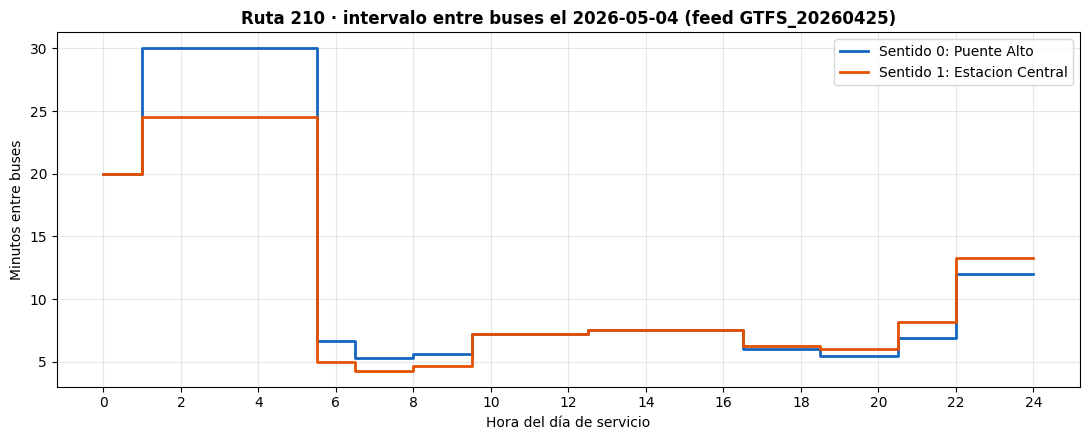

In [17]:
# Intervalo entre buses a lo largo del día, por sentido (gráfico escalonado)
fig, ax = plt.subplots(figsize=(11, 4.5))
colores = {0: "#1565C0", 1: "#E65100"}
for sentido, grupo in frecuencias.groupby("direction_id"):
    x = []; y = []
    for _, fila in grupo.iterrows():
        x += [fila["start_time_s"] / 3600, fila["end_time_s"] / 3600]
        y += [fila["intervalo_min"]] * 2
    ax.plot(x, y, color=colores.get(sentido, "gray"), linewidth=2, label=f"Sentido {sentido}: {grupo['destino'].iloc[0]}")
ax.set_title(f"Ruta {RUTA} · intervalo entre buses el {FECHA} (feed {FEED})", fontweight="bold")
ax.set_xlabel("Hora del día de servicio"); ax.set_ylabel("Minutos entre buses")
ax.set_xticks(range(0, 25, 2)); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

**Los horarios de los buses son plantillas.** Un viaje de bus no trae horas reales sino desplazamientos desde
`00:00:00`; la frecuencia (`frequencies`, con `exact_times = 0`) dice cada cuánto sale. El recorrido de un viaje
(sus paradas en orden) está en `gtfs-stop-times`, siempre filtrando por feed y por viaje:

In [18]:
# Paradas de un viaje de la ruta (stop_times del feed + stops del feed; ~50 filas, no 114 M)
viaje = consulta(f"""
    SELECT trip_id FROM {tabla('trips', FEED)}
    WHERE route_id = '{RUTA_ID}' AND service_id IN ({lista_servicios}) AND direction_id = 0
    ORDER BY trip_id LIMIT 1
""")["trip_id"].iloc[0]

paradas_viaje = consulta(f"""
    SELECT st.stop_sequence, st.arrival_time, st.arrival_time_s, s.stop_name, s.lon, s.lat
    FROM {tabla('stop-times', FEED)} st
    JOIN {tabla('stops', FEED)} s USING (feed_id, stop_id)
    WHERE st.feed_id = '{FEED}' AND st.trip_id = '{viaje}'
    ORDER BY st.stop_sequence
""")
print(f"Viaje {viaje}: {len(paradas_viaje)} paradas")
paradas_viaje.head(8)

Viaje 210-I-L-B00: 68 paradas


,stop_sequence,arrival_time,arrival_time_s,stop_name,lon,lat
0,1,00:00:00,0,PI1840-General Amengual / esq. Av. 5 de Abril,-70.695450,-33.462639
1,2,00:01:58,118,PI909-Concón / esq. Manuel Thompson,-70.695061,-33.456993
2,3,00:02:31,151,PI910-Parada 6 / Concón,-70.695610,-33.455521
3,4,00:04:27,267,PI340-Parada 3 / (M) San Alberto Hurtado,-70.689369,-33.453758
4,5,00:05:18,318,PI341-Parada 1 / (M) Universidad de Santiago,-70.686584,-33.453030
5,6,00:06:39,399,PI440-Parada 3 / San Borja,-70.682175,-33.452084
6,7,00:07:55,475,PI1814-Parada 6 / (M) Estación Central,-70.678062,-33.450905
7,8,00:10:09,609,PA163-Parada 1 / (M) Unión Latinoamericana,-70.670815,-33.448936


---
## 7. Trazados (`gtfs-shapes-lineas`): un ejemplo espacial

`gtfs-shapes` guarda los puntos de cada trazado (61 M de filas); `gtfs-shapes-lineas` guarda **una línea por
`shape_id`** (GeoParquet, `LineString`, EPSG:4326), ya ordenada por `shape_pt_sequence`, con `num_puntos`,
`bbox_*` y `length_m`. Para casi todo conviene la tabla de líneas.

Las dos tablas espaciales (`gtfs-stops` y `gtfs-shapes-lineas`) son **GeoParquet 1.1**; se puede comprobar en el
metadato `geo` del propio archivo. Se leen con DuckDB y la extensión `spatial` (que ya se cargó arriba).

In [19]:
# Versión de GeoParquet declarada en el metadato `geo` del archivo de cada tabla espacial
for tipo in ["stops", "shapes-lineas"]:
    archivo = f"{BASE}/tipo=gtfs-{tipo}/version=v1/part-{FEED.replace('_', '-')}-00000.parquet"
    version, columna = con.execute(f"""
        SELECT json_extract_string(decode(value), '$.version'), json_extract_string(decode(value), '$.primary_column')
        FROM parquet_kv_metadata('{archivo}') WHERE key = 'geo'
    """).fetchone()
    print(f"gtfs-{tipo:14s}  GeoParquet {version}  ·  columna de geometría: {columna}")

gtfs-stops           GeoParquet 1.1.0  ·  columna de geometría: geometry


gtfs-shapes-lineas   GeoParquet 1.1.0  ·  columna de geometría: geometry


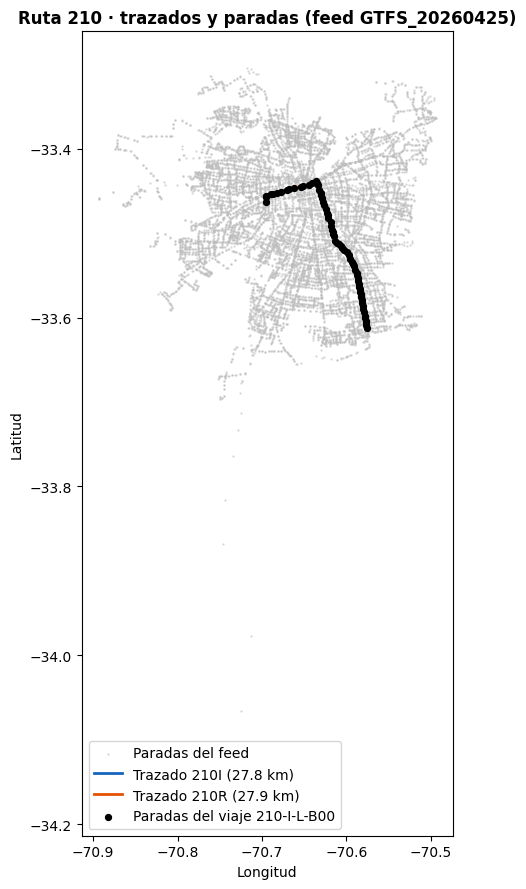

In [20]:
# Trazados de la ruta: el WKT se convierte a listas de coordenadas para dibujarlo
lineas = consulta(f"""
    SELECT shape_id, num_puntos, ROUND(length_m) AS largo_m, ST_AsText(geometry) AS wkt
    FROM {tabla('shapes-lineas', FEED)}
    WHERE shape_id IN (SELECT shape_id FROM {tabla('trips', FEED)} WHERE route_id = '{RUTA_ID}')
""")

def coordenadas(wkt):
    pares = re.findall(r"(-?\d+(?:\.\d+)?) (-?\d+(?:\.\d+)?)", wkt)
    return [float(p[0]) for p in pares], [float(p[1]) for p in pares]

fig, ax = plt.subplots(figsize=(8, 9))
ax.scatter(paradas["lon"], paradas["lat"], s=0.5, c="#bdbdbd", alpha=0.5, label="Paradas del feed")
for color, (_, fila) in zip(["#1565C0", "#E65100"], lineas.iterrows()):
    xs, ys = coordenadas(fila["wkt"])
    ax.plot(xs, ys, color=color, linewidth=2, label=f"Trazado {fila['shape_id']} ({fila['largo_m'] / 1000:.1f} km)")
ax.scatter(paradas_viaje["lon"], paradas_viaje["lat"], s=18, c="black", zorder=3, label=f"Paradas del viaje {viaje}")
ax.set_title(f"Ruta {RUTA} · trazados y paradas (feed {FEED})", fontweight="bold")
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud"); ax.set_aspect("equal"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

### Consulta espacial: ¿qué rutas cruzan el centro de Santiago?

Se aplican los tres niveles de filtro, del más barato al más caro: (1) el feed (un archivo), (2) las columnas
`bbox_*` (estadísticas Parquet, sin decodificar la geometría) y (3) el predicado exacto `ST_Intersects`.

In [21]:
# Rutas cuyo trazado intersecta una caja en el centro de Santiago (lon -70.67..-70.63, lat -33.46..-33.42)
CAJA = dict(xmin=-70.67, ymin=-33.46, xmax=-70.63, ymax=-33.42)
cruzan = consulta(f"""
    SELECT r.route_short_name AS ruta,
           COUNT(DISTINCT s.shape_id)       AS trazados,
           ROUND(SUM(s.length_m) / 1000, 1) AS km_totales
    FROM {tabla('shapes-lineas', FEED)} s
    JOIN (SELECT DISTINCT shape_id, route_id FROM {tabla('trips', FEED)}) t ON t.shape_id = s.shape_id
    JOIN {tabla('routes')} r ON r.feed_id = s.feed_id AND r.route_id = t.route_id
    WHERE s.bbox_xmin <= {CAJA['xmax']} AND s.bbox_xmax >= {CAJA['xmin']}      -- (2) bbox, sin decodificar geometría
      AND s.bbox_ymin <= {CAJA['ymax']} AND s.bbox_ymax >= {CAJA['ymin']}
      AND ST_Intersects(s.geometry, ST_MakeEnvelope({CAJA['xmin']}, {CAJA['ymin']}, {CAJA['xmax']}, {CAJA['ymax']}))   -- (3) exacto
    GROUP BY r.route_short_name
    ORDER BY km_totales DESC
""")
print(f"{len(cruzan)} rutas del feed {FEED} cruzan la caja")
cruzan.head(8)

135 rutas del feed GTFS_20260425 cruzan la caja


,ruta,trazados,km_totales
0,514,5,184.6
1,505,4,142.0
2,426,4,137.2
3,508,4,133.3
4,418,3,118.3
5,106,3,115.6
6,422,3,103.5
7,513,3,92.9


**Trampa de proyecciones en DuckDB.** Para medir en metros hay que proyectar a UTM (zona 19S, `EPSG:32719`).
Escribe siempre `ST_Transform(geometry, 'EPSG:4326', 'EPSG:32719', always_xy := true)`: sin `always_xy` los ejes
salen intercambiados (lat/lon en vez de lon/lat) y el resultado es silenciosamente incorrecto, y la forma corta sin
el CRS de origen falla en archivos GeoParquet 2.0. Abajo, la longitud proyectada coincide con la columna
`length_m` ya calculada. No uses `ST_SetCRS` para "arreglar" vistas.

In [22]:
# Longitud de un trazado: columna length_m vs. proyección explícita a UTM 19S
comparacion = consulta(f"""
    SELECT shape_id,
           ROUND(length_m, 1) AS length_m,
           ROUND(ST_Length(ST_Transform(geometry, 'EPSG:4326', 'EPSG:32719', always_xy := true)), 1) AS largo_utm_19s
    FROM {tabla('shapes-lineas', FEED)}
    WHERE shape_id IN ('{lineas["shape_id"].iloc[0]}', '{lineas["shape_id"].iloc[1]}')
""")
print(comparacion.to_string(index=False))

# Lo mismo sin always_xy: según la versión de DuckDB da error (2.0) o un resultado con ejes intercambiados
try:
    sin_xy = con.execute(f"""
        SELECT ROUND(ST_Length(ST_Transform(geometry, 'EPSG:4326', 'EPSG:32719')), 1)
        FROM {tabla('shapes-lineas', FEED)} WHERE shape_id = '{lineas["shape_id"].iloc[0]}'
    """).fetchone()[0]
    print(f"Sin always_xy (¡no confiar!): {sin_xy}")
except Exception as exc:
    print("Sin always_xy, DuckDB", duckdb.__version__, "falla:", str(exc).splitlines()[0])

shape_id  length_m  largo_utm_19s
    210R   27869.9        27869.9
    210I   27816.2        27816.2


Sin always_xy (¡no confiar!): 17578.9


---
## 8. Cobertura de la vigencia: los días sin feed

Entre feeds hay **días que ningún feed cubre**. `gtfs-vigencia` solo tiene filas para los días con feed, así
que los huecos se encuentran comparando con un calendario completo. Las fechas futuras (hasta el fin de la
vigencia declarada del feed actual) son las que declara el DTPM y pueden cambiar con el próximo feed.

In [23]:
# Días con y sin feed por año, contra un calendario completo
cobertura = consulta(f"""
    WITH rango AS (SELECT MIN(fecha_servicio) AS desde, MAX(fecha_servicio) AS hasta FROM {tabla('vigencia')}),
    dias AS (SELECT unnest(generate_series(desde, hasta, INTERVAL 1 DAY))::DATE AS dia FROM rango)
    SELECT year(d.dia)                                       AS anio,
           COUNT(*) FILTER (WHERE v.fecha_servicio IS NOT NULL) AS con_feed,
           COUNT(*) FILTER (WHERE v.fecha_servicio IS NULL)     AS sin_feed
    FROM dias d
    LEFT JOIN {tabla('vigencia')} v ON v.fecha_servicio = d.dia
    GROUP BY anio ORDER BY anio
""")
total_con, total_sin = int(cobertura["con_feed"].sum()), int(cobertura["sin_feed"].sum())
print(f"Fechas con feed: {total_con:,}  ·  fechas sin feed: {total_sin:,}")

# Los tramos continuos sin feed (técnica de "huecos e islas": fecha - posición = constante dentro del tramo)
huecos = consulta(f"""
    WITH rango AS (SELECT MIN(fecha_servicio) AS desde, MAX(fecha_servicio) AS hasta FROM {tabla('vigencia')}),
    dias AS (SELECT unnest(generate_series(desde, hasta, INTERVAL 1 DAY))::DATE AS dia FROM rango),
    sin AS (
        SELECT d.dia FROM dias d
        LEFT JOIN {tabla('vigencia')} v ON v.fecha_servicio = d.dia
        WHERE v.fecha_servicio IS NULL
    ),
    grupos AS (SELECT dia, dia - (row_number() OVER (ORDER BY dia))::INTEGER AS grupo FROM sin)
    SELECT MIN(dia) AS desde, MAX(dia) AS hasta, COUNT(*) AS dias
    FROM grupos GROUP BY grupo ORDER BY desde
""")
huecos

Fechas con feed: 4,487  ·  fechas sin feed: 261


,desde,hasta,dias
0,2015-07-01,2015-11-30,153
1,2017-07-01,2017-08-29,60
2,2020-01-01,2020-01-10,10
3,2020-08-01,2020-09-06,37
4,2022-07-01,2022-07-01,1


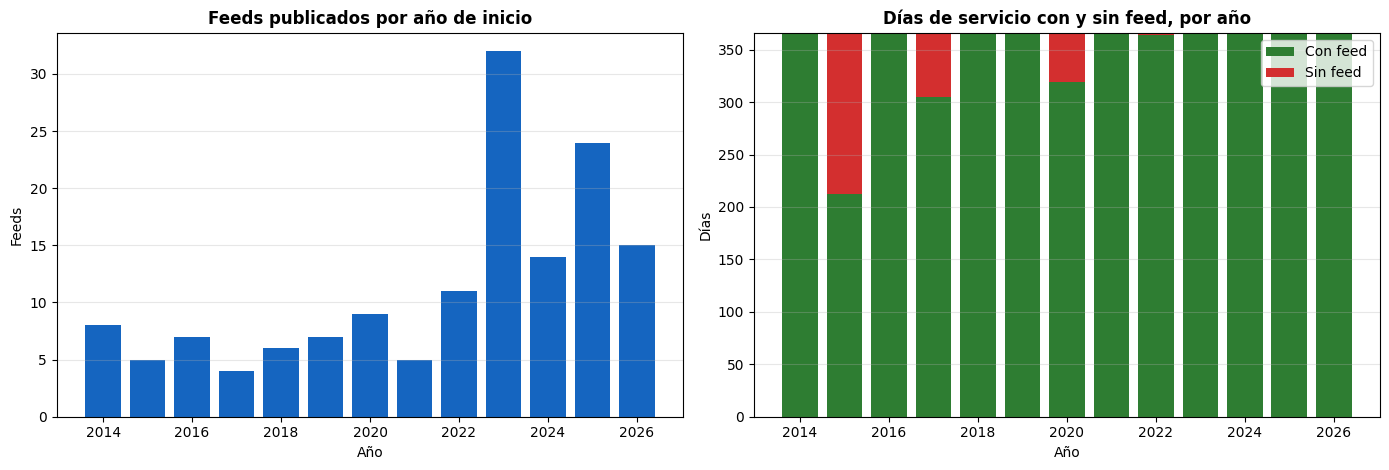

In [24]:
# Gráfico: feeds por año y días cubiertos / sin feed por año
feeds_anio = consulta(f"""
    SELECT year(feed_start_date) AS anio, COUNT(*) AS feeds FROM {tabla('feeds')} GROUP BY anio ORDER BY anio
""")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
ax1.bar(feeds_anio["anio"], feeds_anio["feeds"], color="#1565C0")
ax1.set_title("Feeds publicados por año de inicio", fontweight="bold")
ax1.set_xlabel("Año"); ax1.set_ylabel("Feeds"); ax1.grid(axis="y", alpha=0.3)

ax2.bar(cobertura["anio"], cobertura["con_feed"], color="#2E7D32", label="Con feed")
ax2.bar(cobertura["anio"], cobertura["sin_feed"], bottom=cobertura["con_feed"], color="#D32F2F", label="Sin feed")
ax2.set_title("Días de servicio con y sin feed, por año", fontweight="bold")
ax2.set_xlabel("Año"); ax2.set_ylabel("Días"); ax2.legend(); ax2.grid(axis="y", alpha=0.3)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
plt.tight_layout(); plt.show()

---
## 9. Trampas conocidas

Lo que más confunde al trabajar con estos feeds, comprobado con consultas baratas.

### 9.1 Siempre filtrar por `feed_id` (y preferir el archivo del feed)

Las tablas grandes tienen una copia completa **por feed**; los feeds consecutivos casi no cambian, así que no
hay deduplicación. Sumar o contar sin filtrar mezcla 147 copias de la misma red. Filtrar por `feed_id` sobre el
glob funciona (DuckDB descarta archivos por sus estadísticas) pero abre el footer de los 147 archivos; abrir
directamente el archivo del feed es mucho más rápido:

In [25]:
# Contar todas las filas solo lee footers; filtrar por feed_id sobre el glob vs. abrir el archivo del feed
t0 = time.perf_counter()
total = con.execute(f"SELECT COUNT(*) FROM {tabla('stop-times')}").fetchone()[0]
t1 = time.perf_counter()
n_glob = con.execute(f"SELECT COUNT(*) FROM {tabla('stop-times')} WHERE feed_id = '{FEED}'").fetchone()[0]
t2 = time.perf_counter()
n_archivo = con.execute(f"SELECT COUNT(*) FROM {tabla('stop-times', FEED)}").fetchone()[0]
t3 = time.perf_counter()

print(f"Todos los feeds (solo footers) : {total:>12,} filas  ({t1 - t0:.1f} s)")
print(f"Un feed, glob + WHERE feed_id  : {n_glob:>12,} filas  ({t2 - t1:.1f} s)")
print(f"Un feed, archivo del feed      : {n_archivo:>12,} filas  ({t3 - t2:.1f} s)")

Todos los feeds (solo footers) :  113,969,330 filas  (9.7 s)
Un feed, glob + WHERE feed_id  :    1,093,533 filas  (6.2 s)
Un feed, archivo del feed      :    1,093,533 filas  (0.7 s)


### 9.2 `feed_version` se repite: unir por `feed_id`

In [26]:
consulta(f"""
    SELECT feed_version, COUNT(*) AS feeds, list(feed_id ORDER BY feed_id) AS feed_ids
    FROM {tabla('feeds')}
    GROUP BY feed_version HAVING COUNT(*) > 1
    ORDER BY feeds DESC, feed_version
""")

,feed_version,feeds,feed_ids
0,V125.20240706,3,"[GTFS_20240706, GTFS_20241109, GTFS_20241124]"
1,V115.20240122,2,"[GTFS_20240122, GTFS_20240203]"
2,V131.20250517,2,"[GTFS_20250517, GTFS_20250517_incluye_Maraton]"
3,V64.20210703,2,"[GTFS_20210703, GTFS_20210904]"


### 9.3 Feeds de eventos especiales

Cuatro feeds se publicaron para un evento de un día (maratón, elecciones). Sobre las fechas de sus servicios de un
día, `gtfs-vigencia` elige ese feed aunque la serie diga otro. Es la razón por la que no se resuelve con
`feed_start_date` / `fecha_inicio`.

In [27]:
consulta(f"""
    SELECT f.feed_id, f.feed_kind, MIN(v.fecha_servicio) AS primera_fecha, MAX(v.fecha_servicio) AS ultima_fecha, COUNT(*) AS dias_en_vigencia
    FROM {tabla('vigencia')} v
    JOIN {tabla('feeds')} f USING (feed_id)
    WHERE f.feed_kind = 'evento_especial'
    GROUP BY ALL ORDER BY primera_fecha
""")

,feed_id,feed_kind,primera_fecha,ultima_fecha,dias_en_vigencia
0,GTFS_20230925,evento_especial,2023-09-25,2023-09-29,5
1,GTFS_20241124,evento_especial,2024-11-24,2024-11-24,1
2,GTFS_20250517_incluye_Maraton,evento_especial,2025-05-18,2025-05-18,1
3,GTFS_20260418_Maraton,evento_especial,2026-04-26,2026-04-26,1


### 9.4 Las horas son segundos, y `24:00:00` solo existe en `frequencies`

`arrival_time` / `departure_time` y `start_time` / `end_time` conservan el texto (`HH:MM:SS`, con la hora de un
dígito rellenada: `7:05:00` → `07:05:00`) y cada uno trae su versión en segundos (`*_s`) desde el inicio del día
de servicio. Las horas de `stop_times` del DTPM nunca llegan a 24:00 (el máximo se lee de los footers de los 147
archivos, sin leer datos); las de `frequencies` sí llegan a exactamente `24:00:00`.

In [28]:
max_stop_times = con.execute(f"""
    SELECT MAX(stats_max_value::BIGINT), COUNT(DISTINCT file_name)
    FROM parquet_metadata('{BASE}/tipo=gtfs-stop-times/version=v1/part-*.parquet')
    WHERE path_in_schema = 'arrival_time_s'
""").fetchone()
max_frecuencias = con.execute(f"SELECT MAX(end_time_s), MAX(end_time) FROM {tabla('frequencies')}").fetchone()

print(f"stop_times  : máximo arrival_time_s = {max_stop_times[0]:,} s ({max_stop_times[0] / 3600:.2f} h) en {max_stop_times[1]} archivos")
print(f"frequencies : máximo end_time_s     = {max_frecuencias[0]:,} s  ('{max_frecuencias[1]}')")

stop_times  : máximo arrival_time_s = 86,338 s (23.98 h) en 147 archivos
frequencies : máximo end_time_s     = 86,400 s  ('24:00:00')


### 9.5 Datos tal como se publicaron (con sus defectos)

El pipeline no corrige las fuentes; los defectos conocidos quedan en los datos:

- `GTFS_20200926`: `stop_times` apunta a paradas que no están en `stops.txt` (huérfanas).
- `GTFS_20180922`: la parada `PG1142` aparece dos veces (única clave duplicada del archivo completo).
- `GTFS_20241109`: una fila de `stops` sin `stop_id`.

In [29]:
huerfanas = con.execute(f"""
    SELECT COUNT(*), COUNT(DISTINCT st.stop_id)
    FROM {tabla('stop-times', 'GTFS_20200926')} st
    WHERE NOT EXISTS (SELECT 1 FROM {tabla('stops', 'GTFS_20200926')} s WHERE s.stop_id = st.stop_id)
""").fetchone()
duplicadas = con.execute(f"""
    SELECT stop_id, COUNT(*) FROM {tabla('stops', 'GTFS_20180922')} GROUP BY stop_id HAVING COUNT(*) > 1
""").fetchall()
sin_id = con.execute(f"SELECT COUNT(*) FROM {tabla('stops', 'GTFS_20241109')} WHERE stop_id IS NULL").fetchone()[0]

print(f"GTFS_20200926: {huerfanas[0]:,} filas de stop_times con {huerfanas[1]} paradas que no existen en stops")
print(f"GTFS_20180922: paradas duplicadas {duplicadas}")
print(f"GTFS_20241109: {sin_id} parada sin stop_id")

GTFS_20200926: 3,887 filas de stop_times con 136 paradas que no existen en stops
GTFS_20180922: paradas duplicadas [('PG1142', 2)]
GTFS_20241109: 1 parada sin stop_id


### 9.6 `gtfs-transfers`: tres esquemas en una tabla

`transfers.txt` existe solo en feeds de 2024-10 a 2026-02, con **tres juegos de columnas distintos**; la tabla es
la unión de los tres y las columnas que un feed no trae quedan `NULL`. No tiene clave primaria.

In [30]:
consulta(f"""
    SELECT CASE WHEN COUNT(from_trip_id) > 0 THEN 'con viajes (from/to_trip_id)'
                WHEN COUNT(from_route_id) > 0 THEN 'con rutas (from/to_route_id)'
                ELSE 'solo paradas (from/to_stop_id)' END AS esquema,
           COUNT(*) AS filas
    FROM {tabla('transfers')}
    GROUP BY feed_id
""").groupby("esquema").agg(feeds=("filas", "size"), filas=("filas", "sum")).reset_index()

,esquema,feeds,filas
0,con rutas (from/to_route_id),1,456
1,con viajes (from/to_trip_id),4,56872
2,solo paradas (from/to_stop_id),27,3672


### 9.7 Otras notas

- **Comunas**: `gtfs-stops` no trae comuna; se obtiene uniendo espacialmente con `division-territorial` (dataset de
  `geografia-social`) al momento de la consulta.
- **Día de servicio**: `fecha_servicio` es el día calendario de Santiago. Si se cruza con las posiciones GPS de
  RED Movilidad (particionadas por día UTC), hay que convertir antes la hora UTC a hora de Santiago.
- **Columnas nuevas**: las columnas que el DTPM agregó con el tiempo (`pickup_type`, `timepoint`, `location_type`…)
  son `NULL` en los feeds antiguos.
- **Feeds sin excepciones**: 15 feeds no traen filas en `calendar_dates` (solo 132 de los 147 aparecen en la tabla); para ellos no hay excepciones.

*Datos provistos por [Data Observatory](https://dataobservatory.net) · Fuente: Directorio de Transporte Público Metropolitano (DTPM), feeds GTFS*